### **სტატისტიკის საფუძვლები**

დამატებითი ლიტერატურა: [Statistics](https://stanford.edu/~shervine/teaching/cs-229/refresher-probabilities-statistics)

In [210]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import iqr

In [211]:
# შემთხვევითი მონაცემების გენერაცია
np.random.seed(42)
data = np.random.randint(1, 10, 10)  # 1-დან 10-მდე 10 შემთხვევითი რიცხვი

print(f"📊 მონაცემთა სია: {data}")
print(f"მონაცემთა რაოდენობა: {len(data)}")

📊 მონაცემთა სია: [7 4 8 5 7 3 7 8 5 4]
მონაცემთა რაოდენობა: 10


#### **Min** - მონაცემების მინიმუმი

In [212]:
# მინიმუმის გამოთვლა numpy-ის ფუნქციით
min_value = np.min(data)
print(f"მინიმუმი (Min): {min_value:.2f}")

მინიმუმი (Min): 3.00


#### **Max** - მონაცემების მაქსიმუმი

In [213]:
# მაქსიმუმის გამოთვლა numpy-ის ფუნქციით
max_value = np.max(data)
print(f"მაქსიმუმი (Max): {max_value:.2f}")

მაქსიმუმი (Max): 8.00


#### **Mean** - საშუალო არის ყველა მონაცემის ჯამის გაყოფა ელემენტების რაოდენობაზე

In [214]:
# საშუალოს გამოთვლა 
data_sum = sum(data)
data_n = len(data)
mean_value = data_sum / data_n
print(f"საშუალო (Mean): {mean_value:.2f}")

საშუალო (Mean): 5.80


In [215]:
# საშუალოს გამოთვლა numpy-ის ფუნქციით
mean_value = np.mean(data)
print(f"საშუალო (Mean): {mean_value:.2f}")

საშუალო (Mean): 5.80


#### **Median** - მედიანა არის მონაცემთა სიის შუა მნიშვნელობა, როდესაც მონაცემები დალაგებულია ზრდადობით

In [216]:
sorted_data = sorted(data)
count = len(sorted_data)

if count % 2 == 0: # როცა მონაცემების რაოდენობა ლუწი რიცხვია, 2 ელემენტი გვაქვს სიის შუაში, ვითვლით მათ საშუალოს
    mid1 = sorted_data[count // 2 - 1]
    mid2 = sorted_data[count // 2]
    median_value = (mid1 + mid2) / 2
else:
    median_value = sorted_data[count // 2]
    
print(f"მედიანა (Median): {median_value:.2f}")

მედიანა (Median): 6.00


In [217]:
# მედიანის გამოთვლა numpy-ის ფუნქციით
median_value = np.median(data)
print(f"მედიანა (Median): {median_value:.2f}")

მედიანა (Median): 6.00


#### **Mode**  - მოდა არის ყველაზე ხშირად განმეორებადი მნიშვნელობა

In [218]:
# მოდის გამოთვლა
mode_value = stats.mode(data, keepdims=True)[0][0]
print(f"მოდა (Mode): {mode_value}")

მოდა (Mode): 7


#### **დიაპაზონი**  - ვარიაციის გაქანება 

In [163]:
range_value = np.max(data) - np.min(data) # რამდენად დაშორებულები არიან ყველაზე დიდი და ყველაზე პატარა მონაცემები ერთმანეთისაგან
print(f"ვარიაციის გაქანება (Range): {range_value}")

ვარიაციის გაქანება (Range): 5


#### **Trimmed Mean**

In [226]:
arr = np.array([2, 4, 4, 6, 8, 100])

print("Mean:", round(np.mean(arr), 2)) # Mean can be sensitive to extreme values (outlier).
print("Median:", np.median(arr)) # Median is not influenced by outliers (extreme cases) 

Mean: 20.67
Median: 5.0


ვთქვათ გვაქვს მონაცემთა ერთობლიობა $( x_1, x_2, ..., x_n )$. 

Trimmed Mean-ის გამოსათვლელად ორივე ბოლოდან (ზემოდან და ქვემოდან) ვშლით მონაცემთა გარკვეულ წილს $( p )$.

$$
\text{Trimmed Mean} = \frac{1}{n - 2k} \sum_{i=k+1}^{n-k} x_{(i)}
$$

სადაც
$ k = p \times n $ - წაშლილი ელემენტების რაოდენობა თითო ბოლოდან,

და $ x_{(i)} $ - დალაგებული მნიშვნელობებია ზრდადობით.

In [165]:
def trimmed_mean(data, proportion):
    data = np.sort(data)
    n = len(data)
    k = int(n * proportion)
    trimmed = data[k:n-k]
    return np.mean(trimmed)

print("Trimmed Mean:", trimmed_mean(arr, 0.2)) # მოვჭრით 20%-ს თითო ბოლოდან

Trimmed Mean: 5.5


In [166]:
trimmed_mean = stats.trim_mean(arr, 0.2)
print("Trimmed Mean:", trimmed_mean) 

Trimmed Mean: 5.5


#### **Weighted Mean**

წონიანი საშუალო (Weighted Mean) გამოიყენება მაშინ, როცა მონაცემების თითოეულ მნიშვნელობას განსხვავებული გავლენა აქვს საერთო შედეგზე.

$$
\bar{x}_w = \frac{\sum_{i=1}^{n} w_i x_i}{\sum_{i=1}^{n} w_i}
$$

სადაც

* $(x_i)$ - თითოეული მნიშვნელობაა,
* $(w_i)$ - მათი წონა (weight),
* $(\sum w_i)$ - წონების ჯამი.


ვთქვათ, აბიტურიენტი აბარებს ოთხ საგანს:

| საგანი         | ქულა | წონა |
| -------------- | ---- | ---- |
| ქართული ენა    | 70   | 0.2  |
| მათემატიკა     | 90   | 0.4  |
| უცხო ენა       | 80   | 0.3  |
| ზოგადი უნარები | 75   | 0.1  |


წონიანი საშუალო:

$$
\bar{x}_w = \frac{70 \times 0.2 + 90 \times 0.4 + 80 \times 0.3 + 75 \times 0.1}{0.2 + 0.4 + 0.3 + 0.1}
$$

$$
= \frac{14 + 36 + 24 + 7.5}{1.0} = 81.5
$$

აბიტურიენტის საერთო წონიანი ქულა = 81.5

თუ ჩვეულებრივ საშუალოს გამოვითვლიდით:
$$
(70 + 90 + 80 + 75) / 4 = 78.75
$$

ამიტომ ჩანს, რომ მათემატიკის მაღალი წონა ამაღლებს საბოლოო ქულას, რადგან აბიტურიენტს ამ საგანში მაღალი შედეგი აქვს.

In [167]:
# საგნები, ქულები და წონები
subjects = ["ქართული ენა", "მათემატიკა", "უცხო ენა", "ზოგადი უნარები"]
scores = [70, 90, 80, 75]
weights = [0.2, 0.4, 0.3, 0.1]

# წონიანი საშუალოს გამოთვლა
weighted_mean = sum(score * weight for score, weight in zip(scores, weights)) / sum(weights)

print("საგნები:", subjects)
print("წონიანი საშუალო ქულა:", round(weighted_mean, 2))

საგნები: ['ქართული ენა', 'მათემატიკა', 'უცხო ენა', 'ზოგადი უნარები']
წონიანი საშუალო ქულა: 81.5


In [232]:
# წონიანი საშუალოს გამოთვლა NumPy-ის გამოყენებით
weighted_mean = np.average(scores, weights=weights)

print("საგნები:", subjects)
print("წონიანი საშუალო ქულა:", round(weighted_mean, 2))

საგნები: ['ქართული ენა', 'მათემატიკა', 'უცხო ენა', 'ზოგადი უნარები']
წონიანი საშუალო ქულა: 81.5


#### **Quantile** - კვანტილი არის სტატისტიკური ცნება, რომელიც მონაცემთა განაწილებას თანაბარ ნაწილებად ყოფს

In [171]:
# კვარტილებისა და IQR-ის გამოთვლა
q1 = np.percentile(data, 25) # მონაცემთა ქვედა 25%-ს გამოყოფს
q3 = np.percentile(data, 75) # მონაცემთა ზედა 75%-ს გამოყოფს

iqr_coeff = q3 - q1 # interquartile range 
lower_bound = q1 - 1.5 * iqr_coeff
upper_bound = q3 + 1.5 * iqr_coeff

print(f"Q1 (25% კვანტილი): {q1:.2f}")
print(f"Q3 (75% კვანტილი): {q3:.2f}")
print(f"lower_bound: {lower_bound:.2f}")
print(f"upper_bound: {upper_bound:.2f}")

Q1 (25% კვანტილი): 4.25
Q3 (75% კვანტილი): 7.00
lower_bound: 0.12
upper_bound: 11.12


* ქვედა whisker = ყველაზე პატარა მნიშვნელობა, რომელიც ≥ lower_bound
* ზედა whisker = ყველაზე დიდი მნიშვნელობა, რომელიც ≤ upper_bound

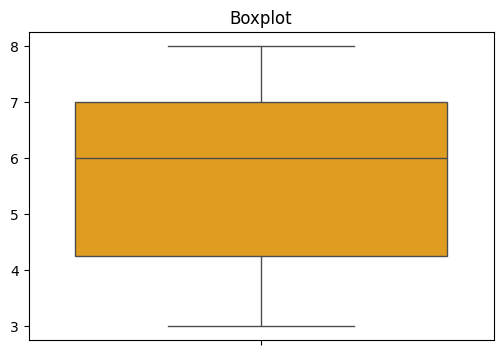

In [101]:
# Boxplot-ის შექმნა
plt.figure(figsize=(6, 4))
sns.boxplot(data, color="orange")
plt.title("Boxplot")
plt.show()

### სტანდარტული გადახრა და მასთან დაკავშირებული შეფასებები

განვიხილოთ ვარიაციის (მონაცემთა გაფანტულობის) შეფასებები:
    
მაგალითად, თუ გვაქვს მონაცემთა ერთობლიობა {1, 4, 4},
მაშინ საშუალო მნიშვნელობაა 3, ხოლო მედიანა - 4.

საშუალოდან გადახრებია:
1 - 3 = -2, 4 - 3 = 1, 4 - 3 = 1.
ეს გადახრები გვიჩვენებს, რამდენად დაშორებულია მონაცემები ცენტრალური მნიშვნელობისგან.

ვარიაციის გასაზომად ერთ-ერთი გზა არის ამ გადახრების საშუალო ტიპური მნიშვნელობის შეფასება.
თუმცა, თუ უბრალოდ ავიღებთ გადახრების საშუალოს, ეს ბევრს არაფერს გვეუბნება - უარყოფითი გადახრები ანულებს დადებითებს.

ამიტომ, მარტივი მიდგომაა ავიღოთ გადახრების აბსოლუტური მნიშვნელობები და შემდეგ მათი საშუალო.
აღებულ მაგალითში გადახრების აბსოლუტური მნიშვნელობებია {2, 1, 1},
და მათი საშუალო არის $(2 + 1 + 1) / 3 = 1.33$

ეს ცნობილია როგორც საშუალო აბსოლუტური გადახრა (Mean Absolute Deviation):

$$
\text{Mean Absolute Deviation} = \frac{\sum_{i=1}^{n} |x_i - \bar{x}|}{n}
$$

სადაც $\bar{x}$ არის საშუალო.

---

ყველაზე ცნობილი ვარიაციის შეფასებებია დისპერსია (Variance) და სტანდარტული გადახრა (Standard Deviation),
რომლებიც ეფუძნება გადახრების კვადრატებს.

დისპერსია არის გადახრების კვადრატების საშუალო,
ხოლო სტანდარტული გადახრა - დისპერსიიდან კვადრატული ფესვი:

$$
\text{Variance} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})^2}{n - 1}
$$
$$
\text{Standard Deviation} = \sqrt{\text{Variance}}
$$

სტანდარტული გადახრა უფრო მარტივად ინტერპრეტირებადია,
რადგან ის იგივე ერთეულებში გამოიხატება, როგორც თავდაპირველი მონაცემები.

#### **Variance** - დისპერსია ზომავს რა სიდიდით განსხვავდება თითოეული მონაცემი საშუალოდან

In [130]:
# კვადრატული გადახრების საშუალო
variance_value = sum((x - mean_value) ** 2 for x in data) / (len(data) - 1)

print("Variance:", round(variance_value, 2))

Variance: 3.29


In [131]:
variance_value = np.var(data, ddof=1)
print(f"Variance: {variance_value:.2f}")

Variance: 3.29


#### **Standard Deviation** - სტანდარტული გადახრა დისპერსიის კვადრატული ფესვია და გვიჩვენებს მონაცემთა საშუალოდ დაშორებას მათი საშუალო მნიშვნელობიდან

In [129]:
std_dev = variance_value ** (1/2)
print(f"Standard Deviation: {std_dev:.2f}")

Standard Deviation: 1.81


In [14]:
std_dev = np.std(data, ddof=1)
print(f"Standard Deviation: {std_dev:.2f}")

Standard Deviation: 1.81


#### **Normal Distribution**

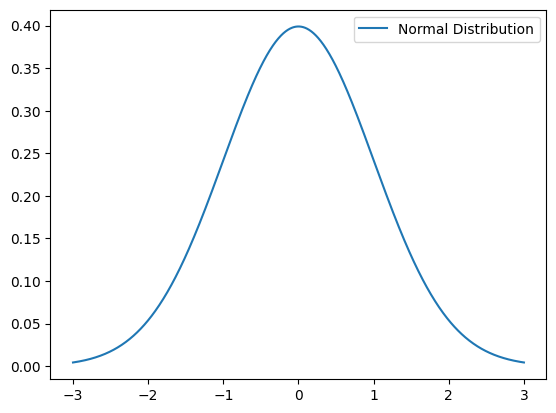

In [19]:
x = np.linspace(-3, 3, 1000)
y = stats.norm.pdf(x, loc=0, scale=1)

plt.plot(x, y, label="Normal Distribution")
plt.legend()
plt.show()

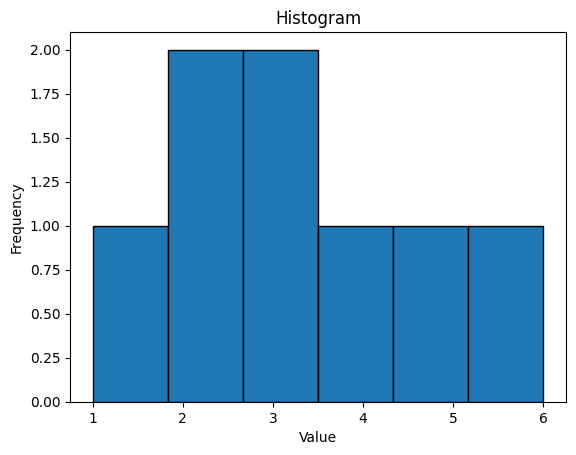

In [243]:
data = [1, 2, 2, 3, 3, 4, 5, 6]

plt.hist(data, bins=6, edgecolor="black")
plt.title("Histogram")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

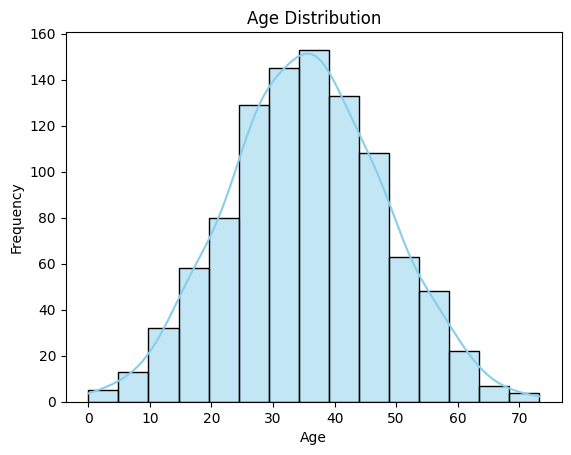

In [244]:
# ასაკის შემთხვევითი მონაცემები (მაგალითად 1000 ადამიანი)
# საშუალო ასაკი 35, სტანდარტული გადახრა 12
ages = np.random.normal(loc=35, scale=12, size=1000)

# უარყოფითი ან ზედმეტად მაღალი მნიშვნელობების დაკორექტირება
ages = np.clip(ages, 0, 90)

# ჰისტოგრამა + KDE ხაზი
sns.histplot(ages, bins=15, kde=True, color="skyblue", edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

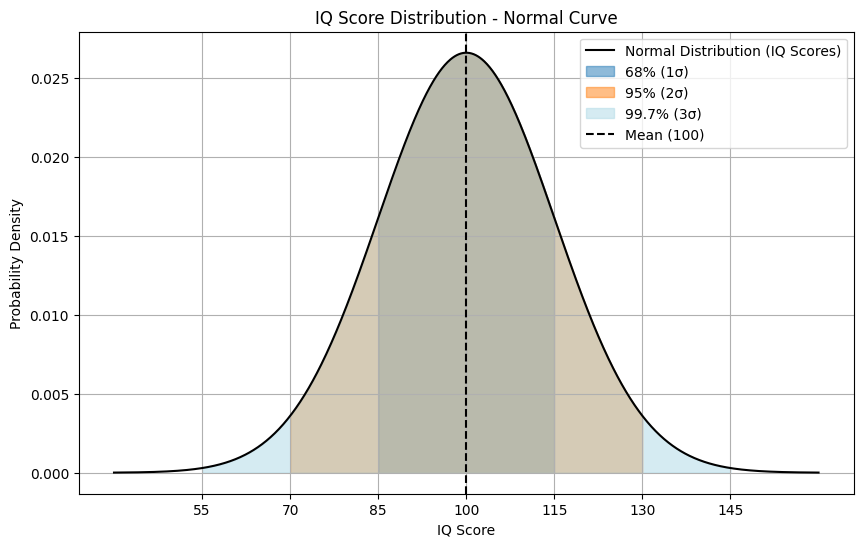

In [21]:
#IQ Score მონაცემების განაწილება
mean = 100  # საშუალო IQ
std_dev = 15  # სტანდარტული გადახრა
x = np.linspace(mean - 4*std_dev, mean + 4*std_dev, 1000)
y = stats.norm.pdf(x, mean, std_dev)

plt.figure(figsize=(10, 6))
plt.plot(x, y, color='black', label="Normal Distribution (IQ Scores)")
plt.fill_between(x, y, where=(x >= mean - std_dev) & (x <= mean + std_dev), color='C0', alpha=0.5, label="68% (1σ)") # საშუალო ± სტანდარტული გადახრა
plt.fill_between(x, y, where=(x >= mean - 2*std_dev) & (x <= mean + 2*std_dev), color='C1', alpha=0.5, label="95% (2σ)") # საშუალო ± 2 * სტანდარტული გადახრა
plt.fill_between(x, y, where=(x >= mean - 3*std_dev) & (x <= mean + 3*std_dev), color='lightblue', alpha=0.5, label="99.7% (3σ)") # საშუალო ± 3 * სტანდარტული გადახრა
plt.axvline(mean, color='black', linestyle='dashed', label="Mean (100)")
plt.xticks([mean - 3*std_dev, mean - 2*std_dev, mean - std_dev, mean, mean + std_dev, mean + 2*std_dev, mean + 3*std_dev],
           ["55", "70", "85", "100", "115", "130", "145"])
plt.title("IQ Score Distribution - Normal Curve")
plt.xlabel("IQ Score")
plt.ylabel("Probability Density")
plt.legend()
plt.grid()
plt.show()

### Outliers აღმოჩენა კვანტილების გამოყენებით

In [249]:
# მონაცემების შექმნა outlier-ებით
np.random.seed(42)
data_normal = np.random.normal(loc=50, scale=10, size=100)  # საშუალო=50, std=10, 100 მონაცემი
outliers = np.array([120, 130, 140, 5, 3])  # მკვეთრად მაღალი და დაბალი მნიშვნელობები
data_with_outliers = np.concatenate([data_normal, outliers])

q1 = np.percentile(data_with_outliers, 25) # მონაცემთა ქვედა 25%-ს გამოყოფს
q3 = np.percentile(data_with_outliers, 75) # მონაცემთა ზედა 25%-ს გამოყოფს
iqr_coeff = iqr(data_with_outliers)

lower_bound = q1 - 1.5 * iqr_coeff
upper_bound = q3 + 1.5 * iqr_coeff

# გავწმინდოთ მონაცემები
outliers = [x for x in data_with_outliers if x < lower_bound or x > upper_bound]
print(f"Bounds: ({lower_bound:.2f}, {upper_bound:.2f}) \n")
print(f"Outliers:")
[print(f"{outlier:.1f}") for outlier in outliers];

Bounds: (27.26, 71.86) 

Outliers:
23.8
120.0
130.0
140.0
5.0
3.0


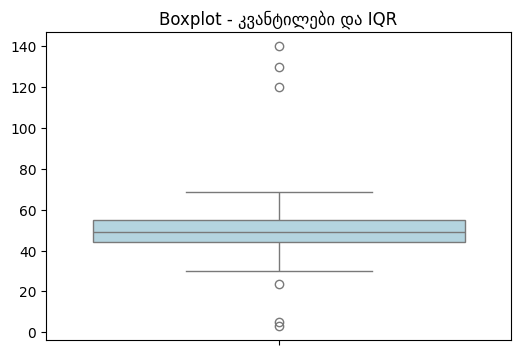

In [113]:
# Boxplot-ის შექმნა
plt.figure(figsize=(6, 4))
sns.boxplot(data_with_outliers, color="lightblue")
plt.title("Boxplot - კვანტილები და IQR")
plt.show()

In [250]:
# Outliers აღმოჩენა საშუალო სტანდარტული გადახრის გამოყენებით
np.random.seed(42)
data_mean = np.mean(data_with_outliers) 
data_std = np.std(data_with_outliers, ddof=1)

lower_bound_s = data_mean - 2 * data_std
upper_bound_s = data_mean + 2 * data_std

# გავწმინდოთ მონაცემები
outliers = [x for x in data_with_outliers if x < lower_bound_s or x > upper_bound_s]
print(f"Mean: {data_mean:.2f}")
print(f"Bounds: ({lower_bound_s:.2f}, {upper_bound_s:.2f})")
print(f"Outliers:")
[print(f"{outlier:.1f}") for outlier in outliers];

Mean: 50.42
Bounds: (15.40, 85.44)
Outliers:
120.0
130.0
140.0
5.0
3.0


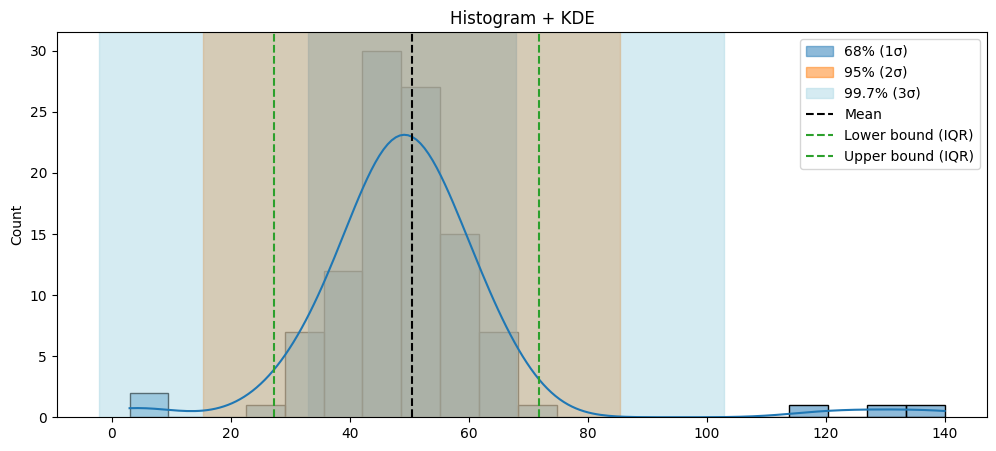

In [251]:
# ნიმუშის ზომა და საშუალო
n = len(data_with_outliers)
sample_mean = np.mean(data_with_outliers)
sample_std = np.std(data_with_outliers, ddof=1)

# Data with outliers განაწილება
plt.figure(figsize=(12, 5))
sns.histplot(data_with_outliers, kde=True, color="C0")
plt.axvspan(sample_mean - sample_std, sample_mean + sample_std, color='C0', alpha=0.5, label="68% (1σ)")
plt.axvspan(sample_mean - 2*sample_std, sample_mean + 2*sample_std, color='C1', alpha=0.5, label="95% (2σ)")
plt.axvspan(sample_mean - 3*sample_std, sample_mean + 3*sample_std, color='lightblue', alpha=0.5, label="99.7% (3σ)")
plt.axvline(sample_mean, color='black', linestyle='dashed', label="Mean")
plt.axvline(lower_bound, color='C2', linestyle='dashed', label="Lower bound (IQR)")
plt.axvline(upper_bound, color='C2', linestyle='dashed', label="Upper bound (IQR)")
plt.title("Histogram + KDE")
plt.legend()
plt.show()

#### **ნდობის ინტერვალი** არის ინტერვალი, რომელშიც ნამდვილი საშუალო დიდი ალბათობით (მაგ. 95%) მდებარეობს.

In [26]:
# ნდობის ინტერვალის გამოთვლა
confidence = 0.95
t_critical = stats.t.ppf((1 + confidence) / 2, df=n-1)
margin_of_error = t_critical * (sample_std / np.sqrt(n))

ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"95% ნდობის ინტერვალი: ({ci_lower:.2f}, {ci_upper:.2f})")

95% ნდობის ინტერვალი: (47.03, 53.81)


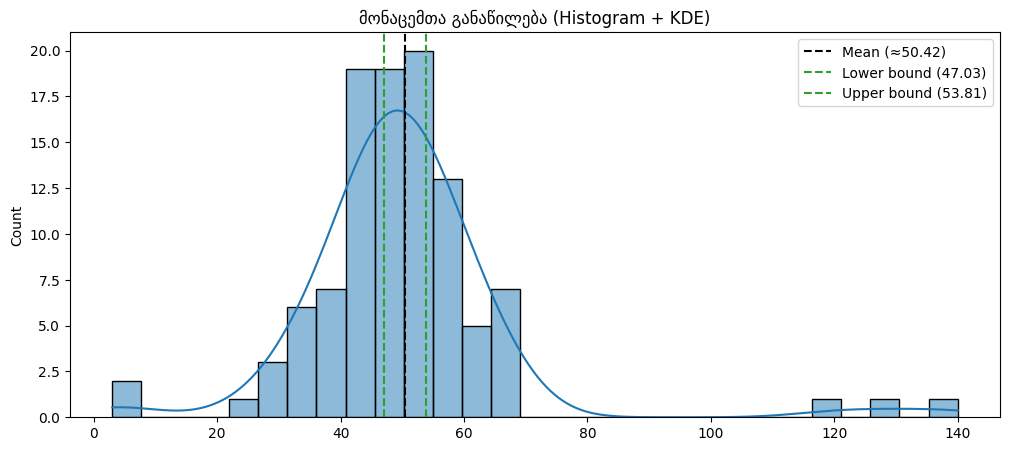

In [27]:
# მონაცემთა განაწილების ვიზუალიზაცია
plt.figure(figsize=(12, 5))
sns.histplot(data_with_outliers, kde=True, color="C0")
plt.axvline(sample_mean, color='black', linestyle='dashed', label="Mean (≈50.42)")
plt.axvline(ci_lower, color='C2', linestyle='dashed', label="Lower bound (47.03)")
plt.axvline(ci_upper, color='C2', linestyle='dashed', label="Upper bound (53.81)")
plt.title("მონაცემთა განაწილება (Histogram + KDE)")
plt.legend()
plt.show()

#### **კორელაცია** და **კოვარიაცია** გამოიყენება ცვლადების ურთიერთკავშირის გასაგებად

კოვარიაცია გვიჩვენებს, აქვს თუ არა ორ ცვლადს საერთო მიმართულება, მაგრამ არ განსაზღვრავს კავშირი რამდენად ძლიერია.  

კოვარიაციის შესაძლო შედეგები:  
- დადებითი კოვარიაცია (+) → თუ ერთი ცვლადის ზრდა იწვევს მეორის ზრდას, მაშინ კოვარიაცია დადებითია.  
- უარყოფითი კოვარიაცია (−) → თუ ერთი ცვლადის ზრდა იწვევს მეორის კლებას, მაშინ კოვარიაცია უარყოფითია.  
- ნულოვანი კოვარიაცია (0) → ორ ცვლადს არ აქვთ ერთმანეთთან დაკავშირებული ცვლილებები (ან კავშირი არ არის ხაზოვანი).  

---
ორ ცვლადს $X$ და $Y$ შორის კოვარიაცია გამოითვლება ასე:  

$Cov(X, Y) = \frac{1}{n} \sum_{i=1}^{n} (X_i - \bar{X}) (Y_i - \bar{Y})$

სადაც:  
- $X_i, Y_i$ → ინდივიდუალური მნიშვნელობები  
- $\bar{X}, \bar{Y}$ → X-ისა და Y-ის საშუალო  
- $n$ → მონაცემთა რაოდენობა  

---

| ფუნქცია       | კოვარიაცია | კორელაცია |
|-------------------|--------------|--------------|
| რას ზომავს? | ორი ცვლადის თანა-ცვლილებას | ორი ცვლადის ურთიერთდამოკიდებულებას |
| განზომილება | დამოკიდებულია ცვლადების ერთეულებზე | სტანდარტიზებული (მერყეობს -1-დან +1-მდე) |
| შედეგის ინტერპრეტაცია | შეიძლება იყოს ნებისმიერი მნიშვნელობა | ყოველთვის [-1, 1] დიაპაზონში |

მთავარი განსხვავება:  
- კოვარიაცია მხოლოდ კავშირის მიმართულებას გვიჩვენებს (დადებითი/უარყოფითი), მაგრამ არ იძლევა კავშირის სიძლიერის შესახებ ინფორმაციას.  
- კორელაცია არის ნორმალიზებული კოვარიაცია, რომელიც ზუსტი კოეფიციენტით გვიჩვენებს კავშირის ძალას.  

---
### კოვარიაციის შეზღუდვები
1. მასშტაბზეა დამოკიდებული → ცვლადების განზომილებები კოვარიაციის მნიშვნელობაზე გავლენას ახდენს.  
2. კავშირის სიძლიერეს არ განსაზღვრავს → მხოლოდ კავშირის მიმართულებას აჩვენებს.  
3. მიზანშეწონილია კორელაციის გამოყენება → თუ კავშირის სიძლიერის დადგენაც გვინდა.  

---

### კოვარიაციის ბიზნესში გამოყენება
- ფინანსებში → ორი აქციის ერთდროული მოძრაობის შესაფასებლად.  
- ეკონომიკაში → კავშირების დასადგენად, მაგალითად, უმუშევრობის დონესა და ინფლაციას შორის.  
- მარკეტინგში → გაყიდვების მონაცემების და მარკეტინგული აქტივობების კავშირის ანალიზისთვის.  

| Student | Study Time (hours) | Exam Score (%) |
| ------- | ------------------ | -------------- |
| A       | 2                  | 55             |
| B       | 3                  | 60             |
| C       | 4                  | 70             |
| D       | 5                  | 75             |
| E       | 6                  | 85             |

In [205]:
data = {
    "Study Time": [2, 3, 4, 5, 6],
    "Exam Score": [55, 60, 70, 75, 85]
}
df = pd.DataFrame(data)

# Covariance
cov = np.cov(df["Study Time"], df["Exam Score"], ddof=1)[0, 1]
print(f"\nCovariance: {cov:.2f}")


Covariance: 18.75


**კორელაციის კოეფიციენტი** არის რიცხვი, რომელიც გამოხატავს კორელაციას ორ ცვლადს შორის.  

კორელაციის ფორმულა (Pearson Correlation Coefficient Formula):  

$r = \frac{\sum (X_i - \bar{X}) (Y_i - \bar{Y})}{\sqrt{\sum (X_i - \bar{X})^2} \cdot \sqrt{\sum (Y_i - \bar{Y})^2}}$

სადაც:  
- $X_i, Y_i$ → ინდივიდუალური მნიშვნელობები ცვლადებისთვის $X$ და $Y$  
- $\bar{X}, \bar{Y}$ → $X$ და $Y$ ცვლადების საშუალო (Mean)  
- $\sum$ → ჯამი 
- სტანდარტიზებულია $[-1, 1]$ დიაპაზონში  

კოეფიციენტის მნიშვნელობები:
- 1 → სრული დადებითი კორელაცია (ერთი ცვლადის ზრდასთან ერთად მეორეც იზრდება)  
- 0 → არ არსებობს ხაზოვანი კორელაცია 
- -1 → სრული უარყოფითი კორელაცია (ერთი ცვლადის ზრდასთან ერთად მეორე კლებულობს)  

![](https://upload.wikimedia.org/wikipedia/commons/3/34/Correlation_coefficient.png)

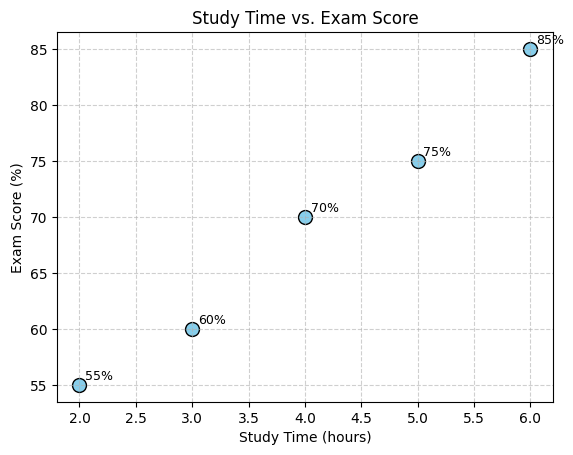

In [208]:
# Scatter plot
plt.scatter(df["Study Time"], df["Exam Score"], color="skyblue", edgecolors="black", s=100)

plt.title("Study Time vs. Exam Score")
plt.xlabel("Study Time (hours)")
plt.ylabel("Exam Score (%)")

plt.grid(True, linestyle="--", alpha=0.6)

for i, row in df.iterrows():
    plt.text(row["Study Time"] + 0.05, row["Exam Score"] + 0.5, f"{row['Exam Score']}%", fontsize=9)

plt.show()

In [206]:
# Correlation coefficient
corr = np.corrcoef(df["Study Time"], df["Exam Score"])[0, 1]

print(f"Correlation coefficient: {corr:.2f}")

Correlation coefficient: 0.99


#### **Hypothesis Testing** - ჰიპოთეზის ტესტირება
 - ნულოვანი ჰიპოთეზა (H₀) და ალტერნატიული ჰიპოთეზა (H₁)
 - p-ღირებულება (p-value) განსაზღვრავს, რამდენად სავარაუდოა შედეგების შემთხვევით მიღება

• H₀ = "no difference between the means of group A and group B" 

• H₁ = "A is different from B" (could be bigger or smaller)

----------------  
• H₀ = "A ≤ B" 

• H₁ = "A > B"

---------------- 
  
• H₀ = "B is not X% greater than A"
  
• H₁ = "B is X% greater than A"

In [200]:
t_stat, p_value = stats.ttest_1samp(data, popmean=50)
print(f"t-სტატისტიკა: {t_stat:.3f}")
print(f"p-ღირებულება: {p_value:.4f}")

if p_value < 0.05:
    print("შედეგი სტატისტიკურად მნიშვნელოვანია (p < 0.05).")
else:
    print("სტატისტიკური მნიშვნელობა არ გამოვლინდა (p > 0.05).")

t-სტატისტიკა: -79.224
p-ღირებულება: 0.0000
შედეგი სტატისტიკურად მნიშვნელოვანია (p < 0.05).


#### **Discrete vs Continuous Variables**
 - Discrete Variable: სასრული მნიშვნელობების ნაკრები (მაგ. სტუდენტების რაოდენობა).
 - Continuous Variable: უსასრულო მნიშვნელობები დიაპაზონში (მაგ. ადამიანის სიმაღლე).

In [31]:
discrete_var = [1, 2, 3, 4, 5]  # Discrete values (e.g., number of cars)
continuous_var = np.random.uniform(0, 10, 10)  # Continuous values

print(f"Discrete: {discrete_var}")
print(f"Continuous: {continuous_var}")

Discrete: [1, 2, 3, 4, 5]
Continuous: [9.44266489 4.74214217 8.62042651 8.44549399 3.19100473 8.28915474
 0.37007635 5.96269878 2.30008837 1.20566886]


#### **Quantitative vs Qualitative Variables**
- Quantitative: რიცხვითი (მაგ. ასაკი)
- Qualitative: კატეგორიული (მაგ. ფერი)

In [32]:
quantitative = [20, 30, 40]
qualitative = ["Red", "Blue", "Green"]

print(f"Quantitative: {quantitative}")
print(f"Qualitative: {qualitative}")

Quantitative: [20, 30, 40]
Qualitative: ['Red', 'Blue', 'Green']


#### **Different Sampling Methods**
- Simple Random Sampling (SRS) - შემთხვევითი შერჩევა
- Stratified Sampling - ჯგუფების მიხედვით
- Systematic Sampling - ყოველ n გამოტოვებით
- Cluster Sampling - შემთხვევითი კლასტერი

In [266]:
sample = np.random.choice(data, 5, replace=True)
print(f"Random Sample: {sample}")

Random Sample: [3 2 4 3 3]


### Open source მონაცემთა სტატისტიკა

#### Bank Marketing Dataset

In [253]:
# Bank Marketing Dataset
df_bank = pd.read_csv("../../datasets/bank_marketing_dataset/bank.csv", sep=';')
df_bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [35]:
# დესკრიპტიული სტატისტიკა
df_bank[['age', 'balance', 'duration']].describe().loc[['mean', 'std', 'min', '50%', 'max']]

,age,balance,duration
mean,41.170095,1422.657819,263.961292
std,10.576211,3009.638142,259.856633
min,19.000000,-3313.000000,4.000000
50%,39.000000,444.000000,185.000000
max,87.000000,71188.000000,3025.000000


In [274]:
df_bank.describe(include=['object'])

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [36]:
# კატეგორიული მონაცემების ანალიზი
# სიხშირე (Frequency)
print(df_bank['job'].value_counts(), "\n")
print(df_bank['marital'].value_counts())

job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
unknown           38
Name: count, dtype: int64 

marital
married     2797
single      1196
divorced     528
Name: count, dtype: int64


In [37]:
# პროცენტული განაწილება
print(df_bank['education'].value_counts(normalize=True) * 100)

education
secondary    51.006415
tertiary     29.860650
primary      14.996682
unknown       4.136253
Name: proportion, dtype: float64


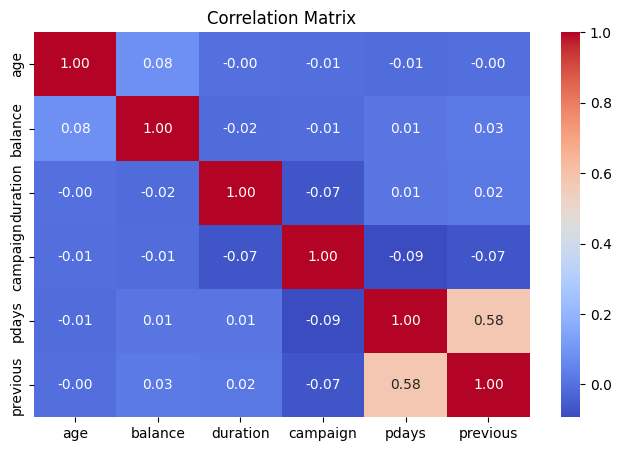

In [38]:
# კორელაცია: შეამოწმე, როგორ კავშირდება სხვადასხვა რიცხვითი ცვლადები ერთმანეთთან
correlation_matrix = df_bank[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

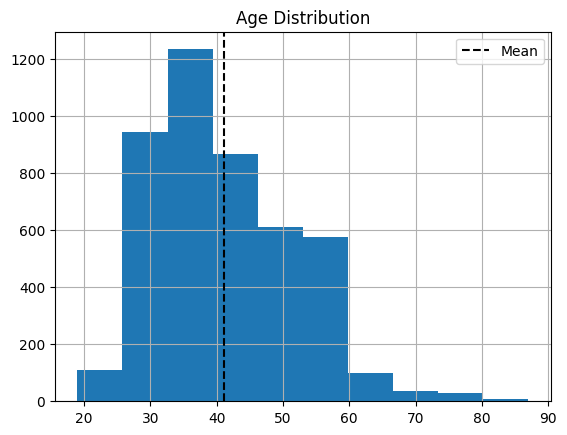

In [39]:
# განაწილების ანალიზი
df_bank['age'].hist()
plt.title('Age Distribution')
plt.axvline(df_bank['age'].mean(), color='black', linestyle='dashed', label="Mean")
plt.legend()
plt.show()

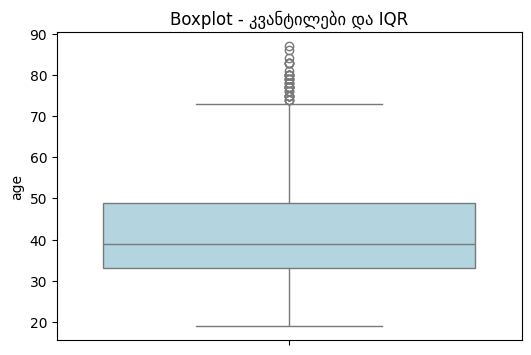

In [40]:
# Boxplot-ის შექმნა
plt.figure(figsize=(6, 4))
sns.boxplot(df_bank['age'], color="lightblue")
plt.title("Boxplot - კვანტილები და IQR")
plt.show()

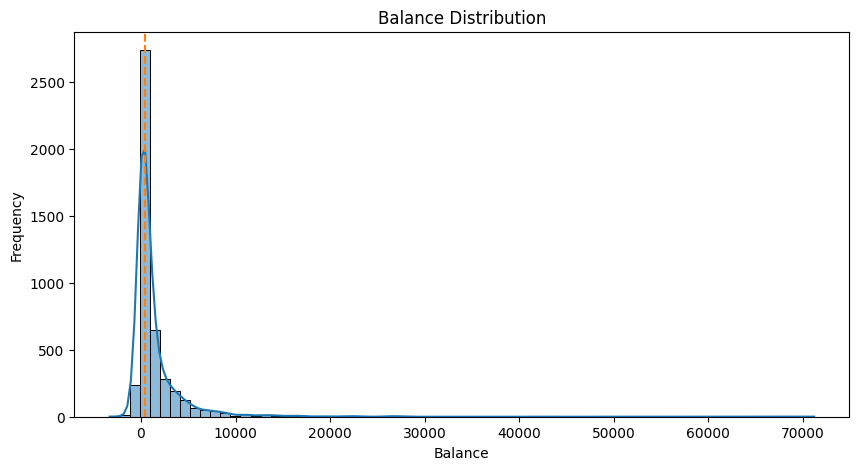

In [286]:
# Balance-ის განაწილება
plt.figure(figsize=(10, 5))
sns.histplot(df_bank["balance"], bins=70, kde=True, color="C0")
plt.axvline(444, color="C1", linestyle='dashed')
plt.title("Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Frequency")
plt.show()

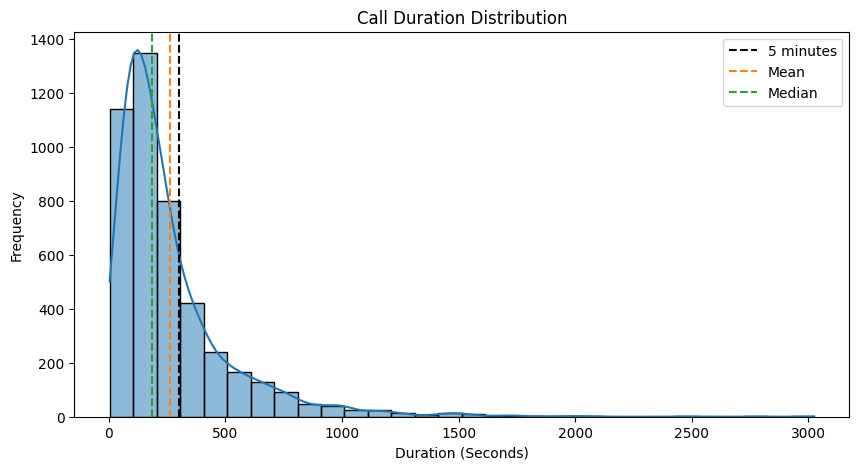

In [42]:
# duration-ის განაწილება
plt.figure(figsize=(10, 5))
sns.histplot(df_bank["duration"], bins=30, kde=True, color="C0")
plt.axvline(300, color='black', linestyle='dashed', label="5 minutes")
plt.axvline(df_bank["duration"].mean(), color='C1', linestyle='dashed', label="Mean")
plt.axvline(df_bank["duration"].median(), color='C2', linestyle='dashed', label="Median")
plt.title("Call Duration Distribution")
plt.xlabel("Duration (Seconds)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

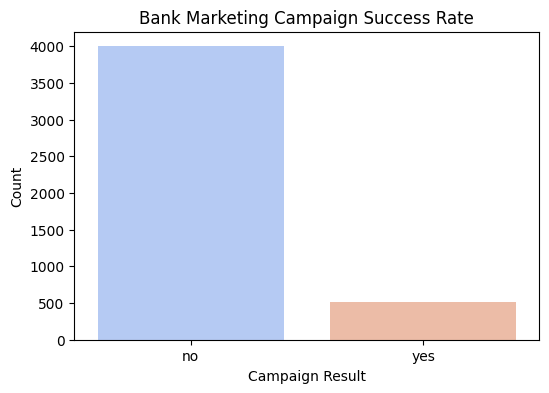

In [43]:
# წარმატებული (yes) და წარუმატებელი (no) კამპანიების რაოდენობა
plt.figure(figsize=(6, 4))
sns.countplot(x="y", data=df_bank, palette="coolwarm", hue="y", legend=False)
plt.title("Bank Marketing Campaign Success Rate")
plt.xlabel("Campaign Result")
plt.ylabel("Count")
plt.show()